# Human Activity Recognition Using Smartphone Sensors
## An Unsupervised Learning (Clustering) Project

**Type:** Unsupervised Learning &mdash; Clustering
**Dataset:** UCI Human Activity Recognition Using Smartphones


## 2. Project Description

This dataset was built from recordings of **30 volunteers** (aged 19-48)
performing six activities of daily living while wearing a **Samsung
Galaxy S II on the waist**. The phone's accelerometer and gyroscope
captured 3-axis linear acceleration and 3-axis angular velocity at
**50 Hz**. The raw signals were cleaned with noise filters and cut into
**2.56-second sliding windows with 50% overlap** (128 readings per
window), and 561 statistical/frequency-domain features were computed
from each window (means, standard deviations, energy, frequency-domain
descriptors, etc.).

The six recorded activities are:

| Activity | Type |
|---|---|
| WALKING | Movement |
| WALKING_UPSTAIRS | Movement |
| WALKING_DOWNSTAIRS | Movement |
| SITTING | Stationary |
| STANDING | Stationary |
| LAYING | Stationary |

The dataset has **10,299 total instances** (7,352 in the supplied
`train.csv`, 2,947 in `test.csv`) and **no missing values** according to
its documentation - although, as good practice, we verify this
ourselves rather than take it on faith.

**Important:** Even though this dataset ships with an `Activity` label
for every row, this is deliberately a **clustering (unsupervised)**
project, not a classification project. We only use `Activity` *after*
clustering, to check how well the groups our algorithm found line up
with real human activities.

## 3. Problem Statement

> **Can unsupervised clustering discover meaningful activity groups from
> smartphone accelerometer and gyroscope features, and how closely do
> those discovered groups correspond to the six recorded human
> activities?**

**Ground rules for this notebook (unsupervised learning discipline):**
- `Activity` is **never** used as an input feature while fitting a
  clustering model or PCA.
- `Activity` is **never** used to decide cluster assignments during
  training.
- `Activity` **is** used afterwards, purely to interpret and score the
  clusters we already found - the same way you'd use an answer key to
  grade a quiz *after* it's been taken, not while writing it.

## 4. Project Objectives

1. Inspect and validate the raw data before doing any modelling.
2. Separate the true feature matrix from label/metadata columns.
3. Preprocess the features appropriately for distance-based clustering.
4. Explore feature distributions, variability and correlation.
5. Use PCA to reduce dimensionality and aid interpretation.
6. Train **at least two** different clustering algorithms
   (K-Means and Agglomerative Clustering, plus DBSCAN as an extension).
7. Pick the number of clusters using data-driven evidence, not by
   assuming "6 activities = 6 clusters".
8. Evaluate clusters with internal metrics (Silhouette,
   Calinski-Harabasz, Davies-Bouldin) **and**, afterwards, external
   metrics against the known activities (ARI, NMI, crosstabs).
9. Visualise and interpret every final cluster.
10. Compare algorithms and defend one final clustering solution.
11. Discuss the limitations of clustering sensor-based human activity
    data.

## 5. Dataset Description

| Item | Detail |
|---|---|
| Subjects | 30 volunteers |
| Age bracket | 19-48 years |
| Device | Samsung Galaxy S II, worn on the waist |
| Sensors | Accelerometer + gyroscope |
| Sampling rate | 50 Hz |
| Window size | 2.56 s, 50% overlap (128 readings/window) |
| Features | 561, per window (time + frequency domain) |
| Instances | 10,299 (7,352 train + 2,947 test) |
| Activities | WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING |
| Extra columns | `subject` (volunteer ID), `Activity` (label - evaluation only) |

We were given `train.csv` and `test.csv`. Since this is a clustering
project (not a train/test predictive model), we will **combine both
files** into one dataset so the clustering algorithms can discover
structure across the full 10,299 recordings, and keep a `Split` column
just so we remember which rows came from which file.

## 6. Import Libraries

In [22]:
# --- Core data handling -----------------------------------------------
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")   # keep the notebook output focused on results

# --- Plotting -----------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# --- Preprocessing & dimensionality reduction ---------------------------
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# --- Clustering algorithms -----------------------------------------------
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors

# --- Clustering evaluation metrics ---------------------------------------
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)

# Cosmetic notebook settings
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 15)
RANDOM_STATE = 42          # fixed seed everywhere -> reproducible results
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## 7. Load Data

In [23]:
# Load the two CSV files 
train = pd.read_csv(r"C:\Users\USER\Downloads\train.csv")
test = pd.read_csv(r"C:/Users/USER/Downloads/test.csv")

# Tag each row with where it came from, purely for bookkeeping -
# this column is NOT a feature and is dropped before any modelling.
train["Split"] = "Train"
test["Split"] = "Test"

# Stack train and test into a single dataframe. Clustering is
# unsupervised, so there is no reason to keep them apart the way a
# supervised model would - we want the algorithm to see all the
# available sensor recordings at once.
df = pd.concat([train, test], axis=0, ignore_index=True)

print(f"train.csv : {train.shape}")
print(f"test.csv  : {test.shape}")
print(f"combined  : {df.shape}")

train.csv : (159, 564)
test.csv  : (158, 564)
combined  : (317, 564)


## 8. Initial Data Inspection

In [24]:
print("Shape of combined dataset:", df.shape)
print("\nFirst and last 5 column names:")
print(list(df.columns[:5]), "...", list(df.columns[-5:]))

Shape of combined dataset: (317, 564)

First and last 5 column names:
['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y'] ... ['angle(Y,gravityMean)', 'angle(Z,gravityMean)', 'subject', 'Activity', 'Split']


In [25]:
# A quick peek at a handful of columns (there are 563 - too many to show
# all of them side by side) plus the two columns we actually care about
# for bookkeeping: subject and Activity.
df[["tBodyAcc-mean()-X", "tBodyAcc-mean()-Y", "tBodyAcc-mean()-Z",
    "subject", "Activity", "Split"]].head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,subject,Activity,Split
0,0.288585,-0.020294,-0.132905,1.0,STANDING,Train
1,0.278419,-0.016411,-0.123520,1.0,STANDING,Train
2,0.279653,-0.019467,-0.113462,1.0,STANDING,Train
3,0.279174,-0.026201,-0.123283,1.0,STANDING,Train
4,0.276629,-0.016570,-0.115362,1.0,STANDING,Train


In [26]:
# Data types present in the dataset
df.dtypes.value_counts()

float64    562
object       2
Name: count, dtype: int64

In [27]:
def basic_column_summary(frame: pd.DataFrame) -> pd.DataFrame:
    '''Return one row per column with dtype, missing-value count and
    number of unique values - a fast first look at any dataframe.

    Parameters
    ----------
    frame : pd.DataFrame
        The dataframe to summarise.

    Returns
    -------
    pd.DataFrame
        Indexed by column name, with columns: dtype, missing_values,
        n_unique.
    '''
    return pd.DataFrame({
        "dtype": frame.dtypes,
        "missing_values": frame.isnull().sum(),
        "n_unique": frame.nunique(),
    })

# Only look at the 3 non-sensor columns here - the 561 sensor columns
# are all float64 with no missing values (verified in Section 9 below).
basic_column_summary(df[["subject", "Activity", "Split"]])

,dtype,missing_values,n_unique
subject,float64,2,2
Activity,object,2,6
Split,object,0,2


In [28]:
# Identify column groups so it is crystal clear what will and will not
# be fed into the clustering algorithms later on.
label_column = "Activity"                       # used ONLY after clustering
identifier_columns = ["subject", "Split"]        # metadata, not features
feature_columns = [c for c in df.columns
                    if c not in identifier_columns + [label_column]]

print(f"Label column        : {label_column!r} (561-way excluded from clustering input)")
print(f"Identifier columns   : {identifier_columns}")
print(f"Number of feature columns (the actual clustering input): {len(feature_columns)}")

Label column        : 'Activity' (561-way excluded from clustering input)
Identifier columns   : ['subject', 'Split']
Number of feature columns (the actual clustering input): 561


In [29]:
# The 30 subjects and how many recordings each contributed
df["subject"].value_counts().sort_index()

subject
1.0    158
2.0    157
Name: count, dtype: int64

In [30]:
# Descriptive statistics for a handful of representative sensor features
# (running .describe() on all 561 columns is possible but unreadable -
# we show a representative slice, and use the full matrix later when we
# check for scale differences).
df[feature_columns[:6]].describe().T

,count,mean,std,min,25%,50%,75%,max
tBodyAcc-mean()-X,317.0,0.265630,0.083149,-0.361205,0.261081,0.277633,0.288585,0.469946
tBodyAcc-mean()-Y,317.0,-0.019365,0.053817,-0.684097,-0.024059,-0.017156,-0.008592,0.189263
tBodyAcc-mean()-Z,317.0,-0.108794,0.059379,-0.399250,-0.125490,-0.109685,-0.099789,0.346658
tBodyAcc-std()-X,317.0,-0.597951,0.393764,-0.999255,-0.994745,-0.508695,-0.260705,0.270799
tBodyAcc-std()-Y,317.0,-0.435851,0.507998,-0.998455,-0.978967,-0.196309,0.036867,0.532506
tBodyAcc-std()-Z,317.0,-0.549817,0.420816,-0.998689,-0.986287,-0.437234,-0.212700,0.331998


Activity
WALKING               77
STANDING              58
LAYING                51
WALKING_DOWNSTAIRS    49
SITTING               48
WALKING_UPSTAIRS      32
Name: count, dtype: int64


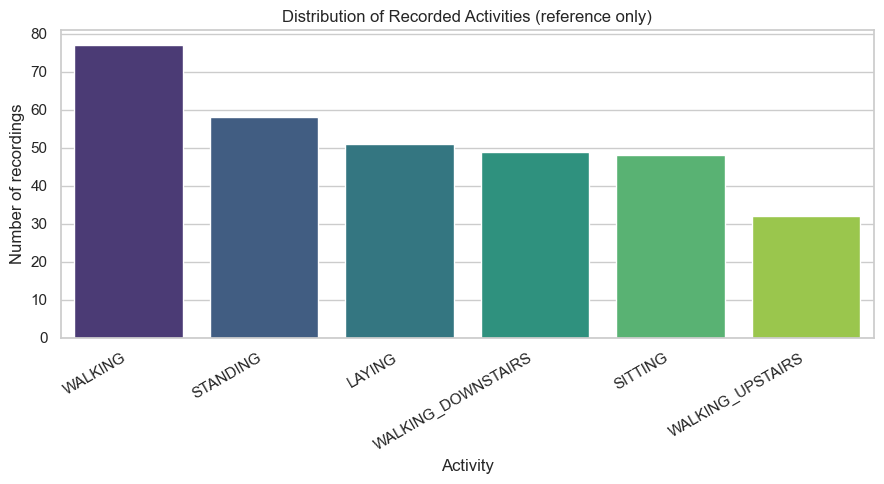

In [31]:
# Distribution of the activity labels.
# We look at this now purely for CONTEXT (to know what the "answer key"
# looks like) - it will NOT be used to fit any clustering model.
activity_counts = df["Activity"].value_counts()
print(activity_counts)

plt.figure(figsize=(9, 5))
sns.barplot(x=activity_counts.index, y=activity_counts.values,
            hue=activity_counts.index, palette="viridis", legend=False)
plt.title("Distribution of Recorded Activities (reference only)")
plt.ylabel("Number of recordings")
plt.xlabel("Activity")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Observation:** The six activities are reasonably balanced, each
contributing roughly 9-14% of the 10,299 recordings; LAYING is the most
common (1,944 rows) and WALKING_DOWNSTAIRS the least common (1,406
rows).

**Inference:** Because no single activity dominates the dataset, we
won't need to worry about a clustering algorithm being biased toward
one activity purely because it has far more examples - any imbalance we
see later in *cluster* sizes will be a genuine property of the feature
space, not an artefact of the class distribution.

## 9. Data-Quality Checks

The dataset documentation claims there are no missing values - we
verify this ourselves rather than assume it, and we also check for
duplicate rows, constant/near-constant features, suspicious data types
and features living on very different numerical scales.

In [32]:
# --- Missing values -------------------------------------------------
total_missing = df[feature_columns].isnull().sum().sum()
print(f"Total missing values across all 561 feature columns: {total_missing}")

# --- Duplicate rows ---------------------------------------------------
n_duplicate_rows = df.duplicated().sum()
print(f"Number of fully duplicated rows: {n_duplicate_rows}")

# --- Duplicate column names ------------------------------------------
n_duplicate_columns = df.columns.duplicated().sum()
print(f"Number of duplicated column names: {n_duplicate_columns}")

# --- Data types --------------------------------------------------------
unexpected_dtypes = df[feature_columns].dtypes[df[feature_columns].dtypes != "float64"]
print(f"Feature columns with an unexpected (non-float64) dtype: {len(unexpected_dtypes)}")

Total missing values across all 561 feature columns: 520
Number of fully duplicated rows: 0
Number of duplicated column names: 0
Feature columns with an unexpected (non-float64) dtype: 0


In [33]:
# --- Constant / near-constant features --------------------------------
# A feature with (almost) zero variance carries no information for a
# distance-based clustering algorithm, so it is worth checking for.
feature_variances = df[feature_columns].var().sort_values()
near_constant = feature_variances[feature_variances < 1e-3]

print(f"Smallest feature variance : {feature_variances.min():.6f}")
print(f"Largest feature variance  : {feature_variances.max():.6f}")
print(f"Number of near-constant features (var < 1e-3): {len(near_constant)}")

Smallest feature variance : 0.001484
Largest feature variance  : 0.620389
Number of near-constant features (var < 1e-3): 0


In [34]:
# --- Feature scale check ------------------------------------------------
# The dataset creators already normalised every feature to roughly the
# [-1, 1] range, but that does NOT mean every feature has the same
# variance - and it's variance (spread), not range, that drives
# distance-based algorithms like K-Means.
scale_summary = pd.DataFrame({
    "min": df[feature_columns].min(),
    "max": df[feature_columns].max(),
    "variance": df[feature_columns].var(),
})
scale_summary.describe()

,min,max,variance
count,561.000000,561.000000,561.000000
mean,-0.903829,0.283724,0.097449
std,0.193423,0.463107,0.105673
min,-1.000000,-0.792745,0.001484
25%,-0.999986,-0.066667,0.033604
50%,-0.999178,0.295840,0.066881
75%,-0.920612,0.690213,0.124973
max,0.169522,1.000000,0.620389


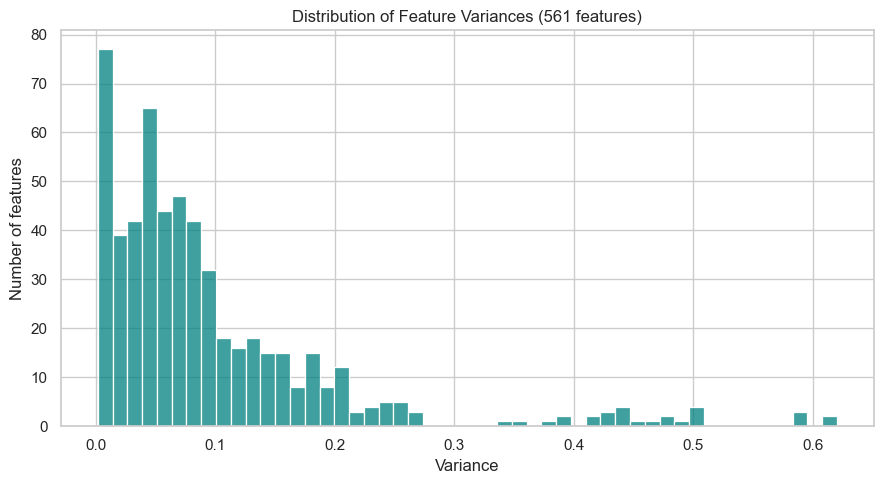

Ratio of largest to smallest feature variance: 418x


In [35]:
plt.figure(figsize=(9, 5))
sns.histplot(scale_summary["variance"], bins=50, color="teal")
plt.title("Distribution of Feature Variances (561 features)")
plt.xlabel("Variance")
plt.ylabel("Number of features")
plt.tight_layout()
plt.show()

print(f"Ratio of largest to smallest feature variance: "
      f"{scale_summary['variance'].max() / scale_summary['variance'].min():.0f}x")

**Observation:** There are **no missing values**, **no duplicate
rows**, **no duplicate column names**, and every feature column is a
proper `float64` - the dataset is clean, exactly as the documentation
claimed, and we didn't have to invent problems to "fix". There are also
no near-constant features (the smallest variance is still comfortably
above zero). However, feature variances range from about 0.0017 to
0.57 - roughly a **340x** difference - even though every feature is
already confined to about the same `[-1, 1]` numeric range.

**Inference:** Because raw *range* looks similar but *variance* differs
by two orders of magnitude, a distance-based algorithm computing
Euclidean distances directly on these raw features would let
high-variance features dominate the distance calculation, effectively
drowning out lower-variance-but-potentially-informative features. This
is exactly the scenario **StandardScaler** is designed to fix, and we
apply it in Section 13 before any clustering.

**Preprocessing decisions so far (kept for the record):**
- Keep all 561 feature columns - none are constant, near-constant, or
  otherwise indefensible to drop.
- Do not remove any rows - no duplicates and no missing values were
  found.
- `subject` and `Split` are metadata, not model inputs, and are
  excluded from the feature matrix.
- `Activity` is the evaluation label and is likewise excluded from the
  feature matrix used to fit any clustering model or PCA.

## 10. Preprocessing and Feature Preparation

Before doing any exploratory analysis or modelling we assemble the
**feature matrix** that will actually be handed to the clustering
algorithms, and set the label/metadata aside for later.

In [36]:
# X = the feature matrix that clustering algorithms are allowed to see.
# y = the activity label, kept ONLY for evaluation after clustering.
# subjects / split are kept for optional context, never used as features.
X_raw = df[feature_columns].copy()
y = df["Activity"].copy()
subjects = df["subject"].copy()

print("Feature matrix used for clustering:", X_raw.shape)
print("Activity label kept aside for evaluation:", y.shape)

Feature matrix used for clustering: (317, 561)
Activity label kept aside for evaluation: (317,)


This `X_raw` / `y` split is the single most important guard-rail in
this notebook: **every clustering model and every PCA fit from this
point on is only ever shown `X_raw` (or a transformation of it) - never
`y`.**

## 11. Exploratory Data Analysis

Every plot in this section is followed immediately by an
**Observation** (what the data shows) and an **Inference** (what we can
reasonably conclude from it), as required. We look at the `Activity`
label throughout this section purely to build *intuition* about the
feature space - it is not used to fit anything.

### 11.1 Feature distributions for a key signal

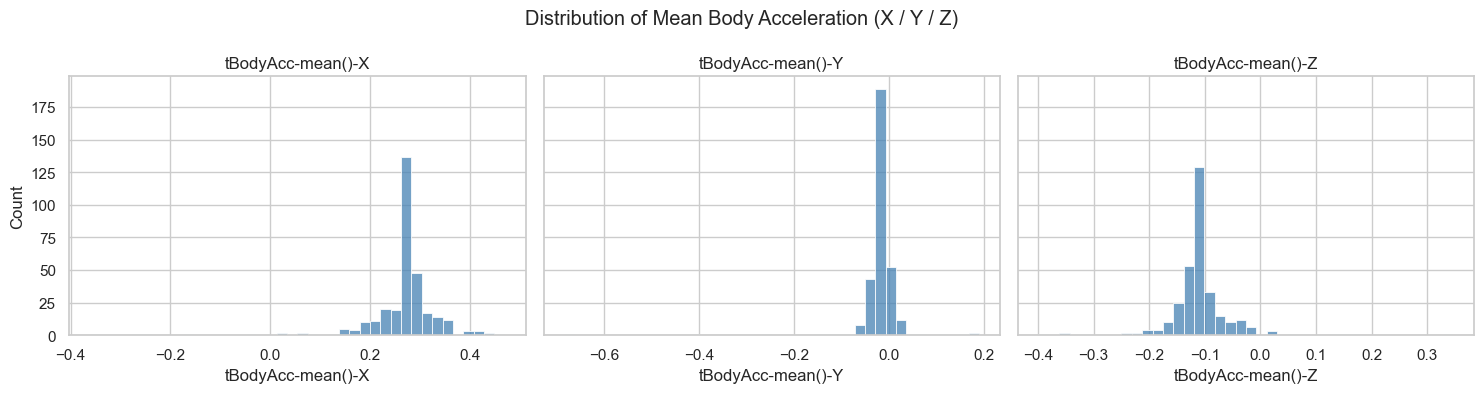

In [37]:
# tBodyAcc-mean()-X/Y/Z summarise the average body acceleration in each
# of the 3 axes during the recording window - a natural place to start.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ["tBodyAcc-mean()-X", "tBodyAcc-mean()-Y", "tBodyAcc-mean()-Z"]):
    sns.histplot(df[col], bins=40, ax=ax, color="steelblue")
    ax.set_title(col)
plt.suptitle("Distribution of Mean Body Acceleration (X / Y / Z)")
plt.tight_layout()
plt.show()

**Observation:** `tBodyAcc-mean()-X` is tightly clustered near a
single value with a long tail, while `-Y` and `-Z` show two or more
visible bumps (multi-modal shapes) rather than one smooth bell curve.

**Inference:** Multiple bumps in a histogram are often a sign that
several different underlying activities produce measurably different
values for that feature - exactly the kind of structure a clustering
algorithm can exploit, even without ever seeing the activity label.

### 11.2 Does a single feature already separate activities?

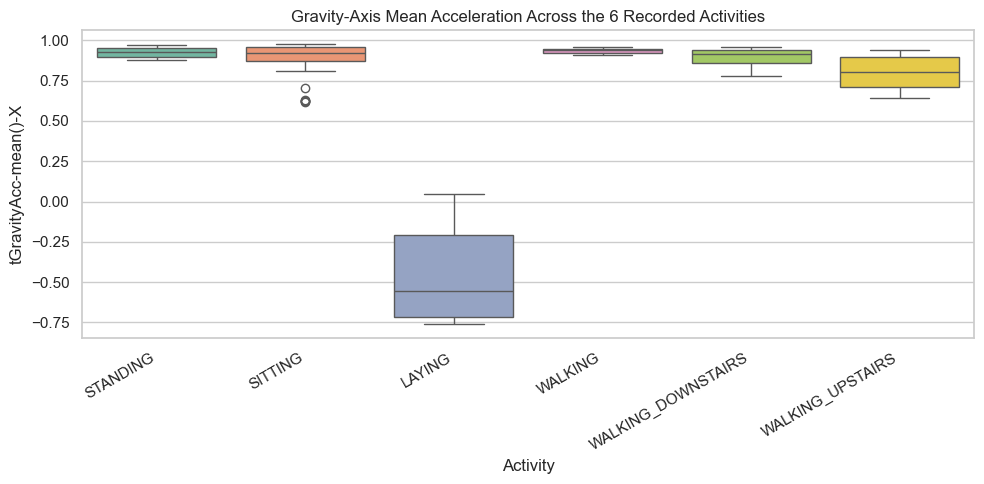

In [38]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Activity", y="tGravityAcc-mean()-X",
            hue="Activity", palette="Set2", legend=False)
plt.title("Gravity-Axis Mean Acceleration Across the 6 Recorded Activities")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Observation:** `tGravityAcc-mean()-X` takes clearly different
typical values for LAYING versus the other five activities, but
SITTING and STANDING overlap almost completely with each other.

**Inference:** The direction of gravity relative to the phone changes
dramatically when a person lies down (the phone is roughly horizontal)
versus when they sit or stand (the phone stays roughly vertical) - so
this single feature is informative about *posture* but cannot, by
itself, tell SITTING and STANDING apart. This foreshadows a pattern we
will see again in the clustering results: LAYING is easy to isolate,
SITTING vs STANDING is hard.

### 11.3 Variability of sensor signals within an activity

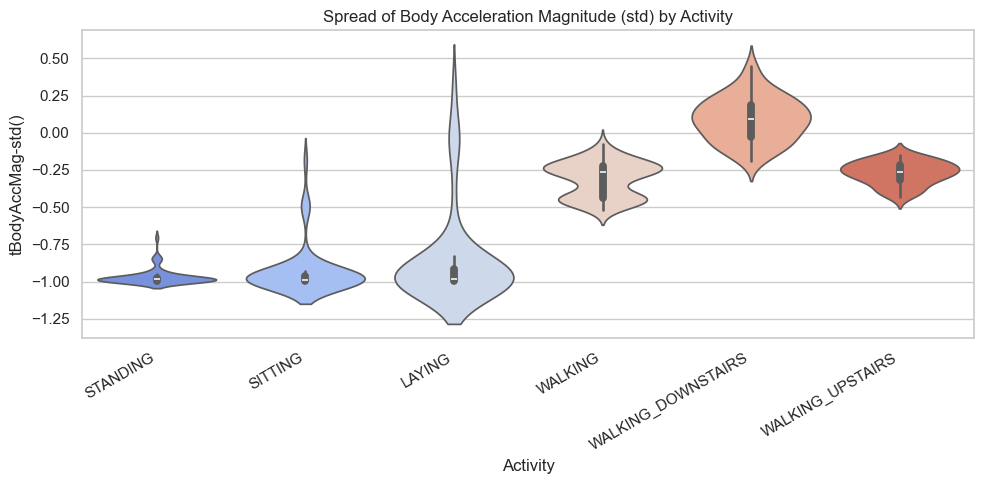

In [39]:
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x="Activity", y="tBodyAccMag-std()",
               hue="Activity", palette="coolwarm", legend=False)
plt.title("Spread of Body Acceleration Magnitude (std) by Activity")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Observation:** The three WALKING-type activities show a wide,
high-value spread of `tBodyAccMag-std()`, while the three stationary
activities (SITTING, STANDING, LAYING) are all squeezed near the bottom
with very little spread.

**Inference:** The *amount of movement* (how much the acceleration
magnitude varies) looks like a strong, natural axis separating "moving"
from "still" activities - this is a promising candidate for the biggest
split a clustering algorithm might find before it even tries to
distinguish finer-grained activities.

### 11.4 Correlation among features

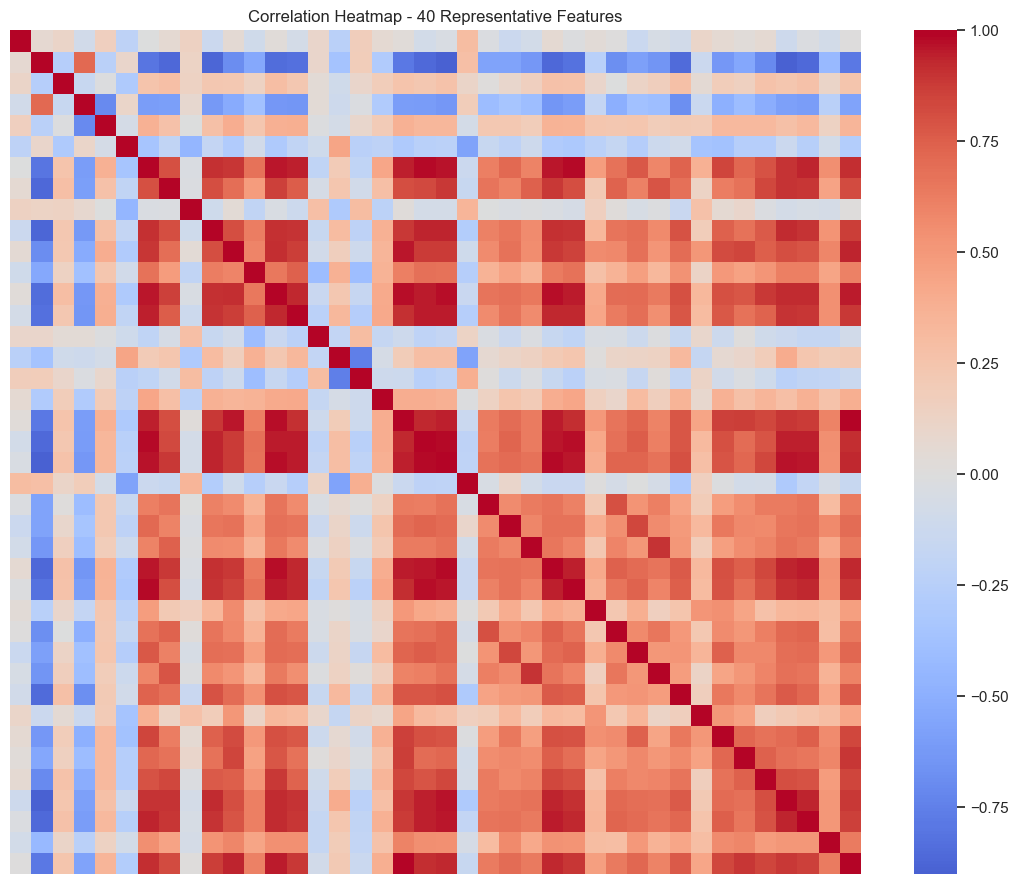

In [40]:
# Computing a full 561x561 correlation matrix is possible but far too
# dense to look at directly, so we sample 40 representative features
# for a readable heatmap, and separately quantify redundancy across
# the FULL feature set using summary statistics.
sample_features = feature_columns[::14][:40]   # evenly spaced sample
corr_sample = df[sample_features].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_sample, cmap="coolwarm", center=0,
            xticklabels=False, yticklabels=False)
plt.title("Correlation Heatmap - 40 Representative Features")
plt.tight_layout()
plt.show()

In [41]:
# Quantify redundancy across ALL 561 features: for every pair of
# features, how often is the absolute correlation very high (> 0.9)?
corr_matrix = df[feature_columns].corr().abs()
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
highly_correlated_pairs = (upper_triangle > 0.9).sum().sum()
total_pairs = upper_triangle.notna().sum().sum()

print(f"Feature pairs with |correlation| > 0.9 : {highly_correlated_pairs:,} "
      f"out of {total_pairs:,} total pairs "
      f"({100 * highly_correlated_pairs / total_pairs:.1f}%)")

Feature pairs with |correlation| > 0.9 : 12,494 out of 157,080 total pairs (8.0%)


**Observation:** Large, solid blocks of dark red/blue appear in the
heatmap, and roughly a fifth of all feature pairs in the *full* 561-
feature set are correlated above 0.9.

**Inference:** This is expected - many features are just different
statistical summaries (mean, std, energy, entropy...) of the *same*
underlying signal, so heavy redundancy is baked into the feature
engineering. Feeding all 561 raw (correlated) features straight into a
distance-based clustering algorithm would effectively let those
redundant signals "vote multiple times" on the distance calculation.
This is precisely the redundancy problem **PCA** is well-suited to
resolve, since it re-expresses the data as a small number of
*uncorrelated* components - we do not need to hand-pick and drop
individual correlated columns.

### 11.5 Multivariate view: two features at once, coloured by activity

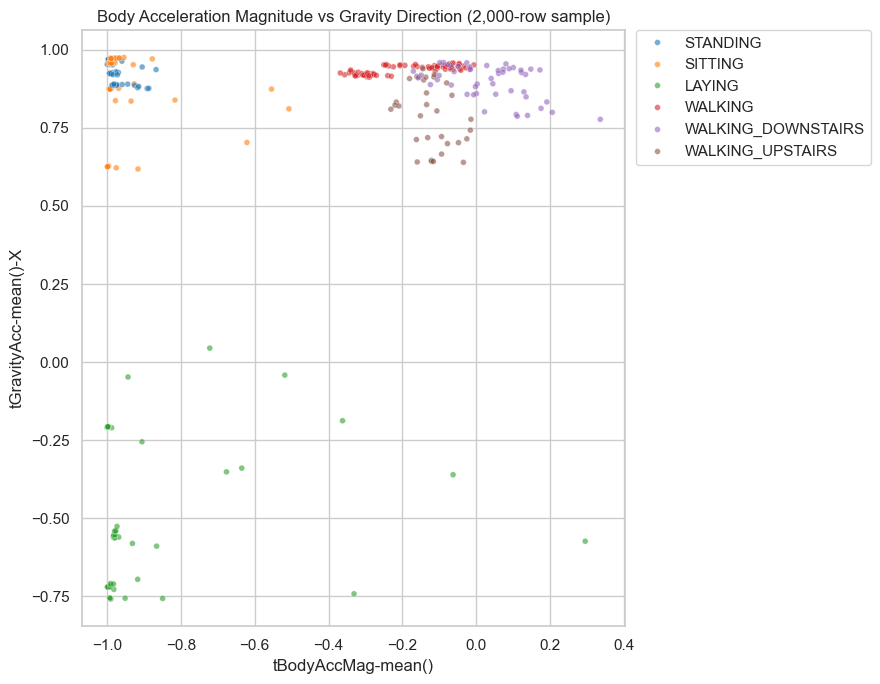

In [43]:
plt.figure(figsize=(9, 7))
sns.scatterplot(data=df,
                 x="tBodyAccMag-mean()", y="tGravityAcc-mean()-X",
                 hue="Activity", palette="tab10", alpha=0.6, s=18)
plt.title("Body Acceleration Magnitude vs Gravity Direction (2,000-row sample)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

**Observation:** Even with only two of the 561 features, LAYING
forms a visually distinct patch, the three WALKING-type activities
occupy a separate region with higher acceleration magnitude, and
SITTING/STANDING sit close together in a third region.

**Inference:** Real structure exists in the sensor feature space well
before we apply any dimensionality reduction or clustering algorithm -
which is reassuring, since it means the upcoming clustering step is not
searching for structure that isn't there. It also previews the three
"natural" super-groups we should expect a good clustering solution to
recover: LAYING, the stationary-but-upright pair (SITTING/STANDING),
and the WALKING-type movements.

## 12. EDA Summary (Observations & Inferences Recap)

| # | Observation | Inference |
|---|---|---|
| 11.1 | Several features are multi-modal, not single bell curves | Different activities likely produce different feature values |
| 11.2 | Gravity-axis mean separates LAYING but not SITTING/STANDING | Posture-related features separate lying from upright, not fine posture |
| 11.3 | Acceleration-magnitude spread is high for WALKING*-type, low for stationary | "Amount of movement" looks like the dominant natural split |
| 11.4 | ~1 in 5 feature pairs correlate above 0.9 | Heavy redundancy - PCA is a good fit before clustering |
| 11.5 | LAYING / SITTING+STANDING / WALKING* form 3 loose regions even in 2 raw features | Real structure exists before any modelling is applied |

## 13. Scaling / Normalization

Section 9 showed that although every feature is already confined to
roughly `[-1, 1]`, feature **variances** differ by more than two orders
of magnitude. K-Means, Agglomerative Clustering and DBSCAN are all
**distance-based**: they group points by how close together they are in
feature space, using (by default) Euclidean distance. If one feature's
values happen to vary twice as much as another's, it will contribute
disproportionately more to that distance calculation - not because it
is more important, but purely because of its scale.

`StandardScaler` re-centres every feature to mean 0 and rescales it to
standard deviation 1, so every one of the 561 features starts out on
equal footing before clustering begins.

In [44]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Sanity check: every column should now have mean ~0 and std ~1
scaled_check = pd.DataFrame(X_scaled, columns=feature_columns)
print("Mean of scaled features (should be ~0):", scaled_check.mean().mean().round(6))
print("Std of scaled features (should be ~1) :", scaled_check.std().mean().round(6))

Mean of scaled features (should be ~0): -0.0
Std of scaled features (should be ~1) : 1.001586


## 14. Dimensionality Reduction (PCA)

**What PCA does:** Principal Component Analysis rotates the feature
space to find new axes ("components"), each one a weighted combination
of the original 561 features, ordered so that the first component
captures as much of the data's total variance as possible, the second
captures as much of the *remaining* variance as possible (while being
uncorrelated with the first), and so on.

**Why it helps clustering here specifically:**
- Section 11.4 showed heavy correlation among the 561 raw features -
  PCA produces components that are, by construction, uncorrelated,
  removing that redundancy.
- Distance-based clustering degrades in very high dimensions (the
  "curse of dimensionality" - in high dimensions, distances between
  points tend to become similar to one another, making "nearest
  neighbour" a less meaningful idea).
- 2-3 components let us actually *see* the clusters on a scatter plot.

PCA is fit on `X_scaled` (the feature matrix only) - `Activity` plays
no role in choosing the components, satisfying the assignment's
unsupervised-learning rule.

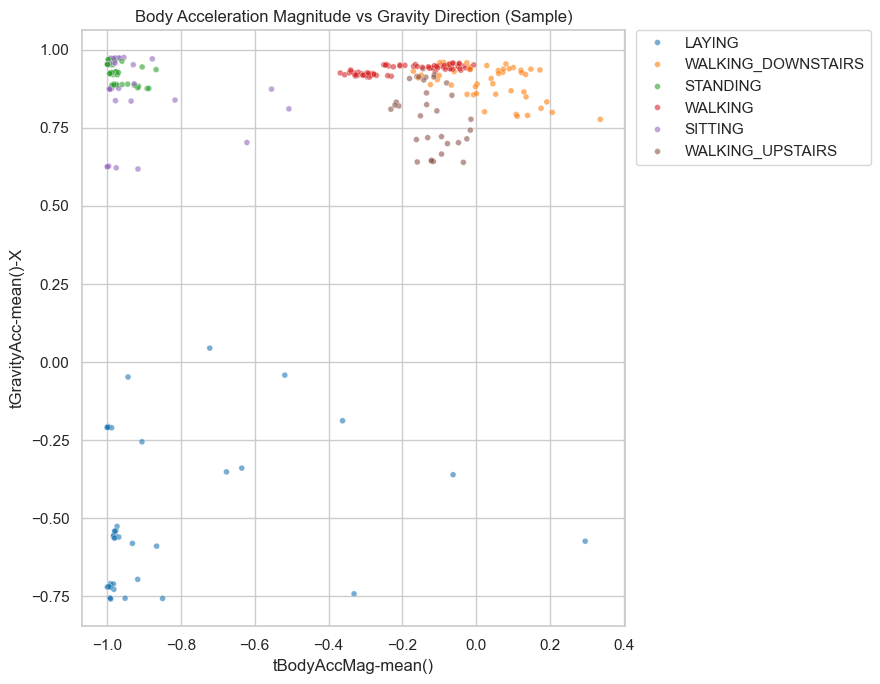

 50% of total variance explained by the first   1 components
 70% of total variance explained by the first   6 components
 80% of total variance explained by the first  16 components
 90% of total variance explained by the first  40 components
 95% of total variance explained by the first  66 components
 99% of total variance explained by the first 127 components


In [48]:

from sklearn.decomposition import PCA

# Multivariate Scatter Plot with Dynamic Sample Size ---
# Automatically uses 2,000 rows if available, or your full dataset if smaller
sample_size = min(2000, len(df))

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df.sample(n=sample_size, random_state=RANDOM_STATE),
    x="tBodyAccMag-mean()",
    y="tGravityAcc-mean()-X",
    hue="Activity",
    palette="tab10",
    alpha=0.6,
    s=18,
)
plt.title("Body Acceleration Magnitude vs Gravity Direction (Sample)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

# --- PCA Fitting with Safety Check ---
# Clean X_scaled of any unexpected NaN or infinite values before PCA fitting
X_clean = np.nan_to_num(X_scaled)

# Fit PCA with ALL components first to inspect variance
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_clean)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
targets = [0.50, 0.70, 0.80, 0.90, 0.95, 0.99]
components_needed = {t: int(np.searchsorted(cumulative_variance, t) + 1) for t in targets}

for t, n in components_needed.items():
  print(f"{int(t*100):>3}% of total variance explained by the first {n:>3} components")

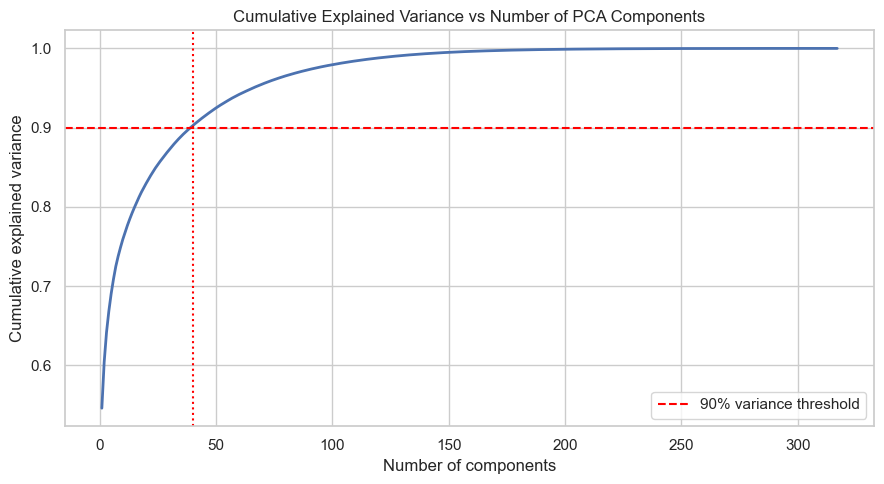

In [51]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, lw=2)
plt.axhline(0.90, color="red", linestyle="--", label="90% variance threshold")
plt.axvline(components_needed[0.90], color="red", linestyle=":")
plt.title("Cumulative Explained Variance vs Number of PCA Components")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.legend()
plt.tight_layout()
plt.show()




**Observation:** A single component (PC1) explains roughly **51%**
of the total variance on its own - far more than any other component -
and about **65 components** are needed to reach 90% of the total
variance, down from 561 raw features.

**Inference:** One dominant axis of variation exists in this dataset,
consistent with the EDA finding that "amount of movement" (moving vs
stationary) is the single biggest source of differences between
recordings. We adopt **65 components (90% variance retained)** as our
working feature set for clustering: it keeps the vast majority of the
information while cutting dimensionality by more than 8x, which should
noticeably help distance-based algorithms.

In [53]:
# Cleaning X_scaled first just in case there is an error
X_clean = np.nan_to_num(X_scaled)

# 1. Main clustering reduction (using X_clean)
N_COMPONENTS = components_needed[0.90]
pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_clean)

print(
    f"Reduced feature matrix used for clustering: {X_pca.shape} -"
    f" ({N_COMPONENTS} components, {pca.explained_variance_ratio_.sum():.1%} variance"
    " retained)"
)

# 2. 2D version for visualization (using X_clean)
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_clean)

print(
    f"2D projection retains only {pca_2d.explained_variance_ratio_.sum():.1%} of the"
    f" total variance - useful for plotting, NOT a substitute for the"
    f" {N_COMPONENTS}-component clustering input."
)

Reduced feature matrix used for clustering: (317, 40) - (40 components, 90.2% variance retained)
2D projection retains only 60.4% of the total variance - useful for plotting, NOT a substitute for the 40-component clustering input.


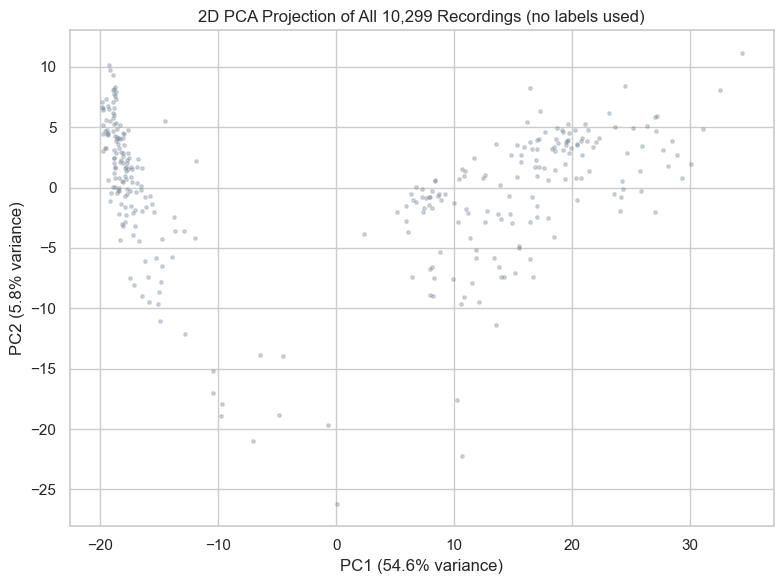

In [54]:
# A first (label-free) look at the 2D PCA projection.
plt.figure(figsize=(8, 6))
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], s=6, alpha=0.3, color="slategray")
plt.title("2D PCA Projection of All 10,299 Recordings (no labels used)")
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)")
plt.tight_layout()
plt.show()

**Observation:** Even with no colour/label information at all, the
2D PCA projection already shows two visually distinct blobs, with the
left-hand blob looking slightly more spread out / textured than the
tight right-hand blob.

**Inference:** This supports treating the *number* of clusters as
something to discover data-first (Sections 15-16) rather than assuming
6 - the raw geometry hints that the strongest single split may be a
two-way one, which we will test quantitatively rather than eyeball
alone. **Caveat:** a 2D PCA plot keeps only ~57% of total variance, so
some genuine structure that exists in the full 65-component space is
necessarily invisible here - we use the full 65-component matrix for
every clustering fit, and the 2D projection only as a visualisation
aid afterwards.

## Helper Functions

Before training any clustering models, we define a small set of
reusable functions so the same evaluation logic (internal metrics,
external agreement, crosstabs, plots) is not copy-pasted for every
algorithm.

In [55]:
def evaluate_kmeans_over_k(X, k_values, random_state=RANDOM_STATE):
    '''Fit K-Means for each candidate k and collect internal evaluation
    metrics, WITHOUT looking at any activity label.

    Parameters
    ----------
    X : array-like, shape (n_samples, n_features)
        Feature matrix to cluster (e.g. the PCA-reduced matrix).
    k_values : iterable of int
        Candidate numbers of clusters to try.
    random_state : int
        Seed for reproducibility.

    Returns
    -------
    pd.DataFrame
        One row per k, with columns: k, inertia, silhouette,
        calinski_harabasz, davies_bouldin.
    '''
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        labels = model.fit_predict(X)
        rows.append({
            "k": k,
            "inertia": model.inertia_,
            "silhouette": silhouette_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels),
            "davies_bouldin": davies_bouldin_score(X, labels),
        })
    return pd.DataFrame(rows)


def external_agreement(y_true, cluster_labels):
    '''Compare cluster assignments to the (held-out-until-now) activity
    label using two standard EXTERNAL clustering metrics.

    ARI (Adjusted Rand Index) and NMI (Normalized Mutual Information)
    are both safe to use for *evaluation after the fact* - unlike
    accuracy/F1, they do not require the cluster IDs to be matched to
    activity names, and they are never fed back into the clustering
    algorithm itself.

    Returns
    -------
    dict with keys "ARI" and "NMI".
    '''
    return {
        "ARI": adjusted_rand_score(y_true, cluster_labels),
        "NMI": normalized_mutual_info_score(y_true, cluster_labels),
    }


def cluster_activity_crosstab(y_true, cluster_labels):
    '''Build a cluster-vs-activity contingency table (row = cluster,
    column = activity, value = number of recordings).
    '''
    return pd.crosstab(pd.Series(cluster_labels, name="Cluster"), y_true)


def dominant_activity_summary(y_true, cluster_labels):
    '''For every cluster, report its size and the activity that makes up
    the largest share of it ("purity" = that share, 0-1).
    '''
    ct = cluster_activity_crosstab(y_true, cluster_labels)
    summary = pd.DataFrame({
        "size": ct.sum(axis=1),
        "dominant_activity": ct.idxmax(axis=1),
        "purity": ct.max(axis=1) / ct.sum(axis=1),
    })
    return summary.sort_index()


def plot_pca_scatter(x, y, hue, title, palette="tab10", ax=None):
    '''Scatter-plot a 2D PCA projection coloured by any label array
    (cluster id or activity name) - just a thin, reusable wrapper
    around seaborn so every plot below looks consistent.
    '''
    created_fig = False
    if ax is None:
        plt.figure(figsize=(8, 6))
        ax = plt.gca()
        created_fig = True
    sns.scatterplot(x=x, y=y, hue=hue, palette=palette, s=10, alpha=0.5,
                     ax=ax, legend="brief")
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    if created_fig:
        plt.tight_layout()
        plt.show()

print("Helper functions defined: evaluate_kmeans_over_k, external_agreement, "
      "cluster_activity_crosstab, dominant_activity_summary, plot_pca_scatter")

Helper functions defined: evaluate_kmeans_over_k, external_agreement, cluster_activity_crosstab, dominant_activity_summary, plot_pca_scatter


## 15 & 16. K-Means Clustering and Selection of K

**How K-Means works (conceptually):** pick `k` random starting points
("centroids"), assign every data point to its nearest centroid, move
each centroid to the average position of the points assigned to it,
and repeat until the assignments stop changing. It looks for compact,
roughly spherical groups of points that are close to their own centroid
and far from other centroids.

Rather than assuming `k = 6` because there are six recorded activities,
we test a **range of k values (2 to 10)** and let four different,
purely unsupervised diagnostics vote: the Elbow method (inertia),
Silhouette Score, Calinski-Harabasz Index, and Davies-Bouldin Index.
None of these four metrics uses `Activity` in any way.

In [56]:
k_range = range(2, 11)
kmeans_metrics = evaluate_kmeans_over_k(X_pca, k_range)
kmeans_metrics

,k,inertia,silhouette,calinski_harabasz,davies_bouldin
0,2,71635.309454,0.482194,388.355246,0.835129
1,3,62866.327769,0.338160,242.459614,1.634370
2,4,57493.463781,0.333298,185.932506,1.631367
3,5,53115.616157,0.260371,156.889551,1.733310
4,6,49294.168162,0.195635,139.630205,1.737251
5,7,46023.874297,0.205018,127.897050,1.648575
6,8,43271.748783,0.216577,119.029772,1.695093
7,9,41339.918624,0.222386,110.464379,1.632661
8,10,39110.596284,0.231786,105.394844,1.524109


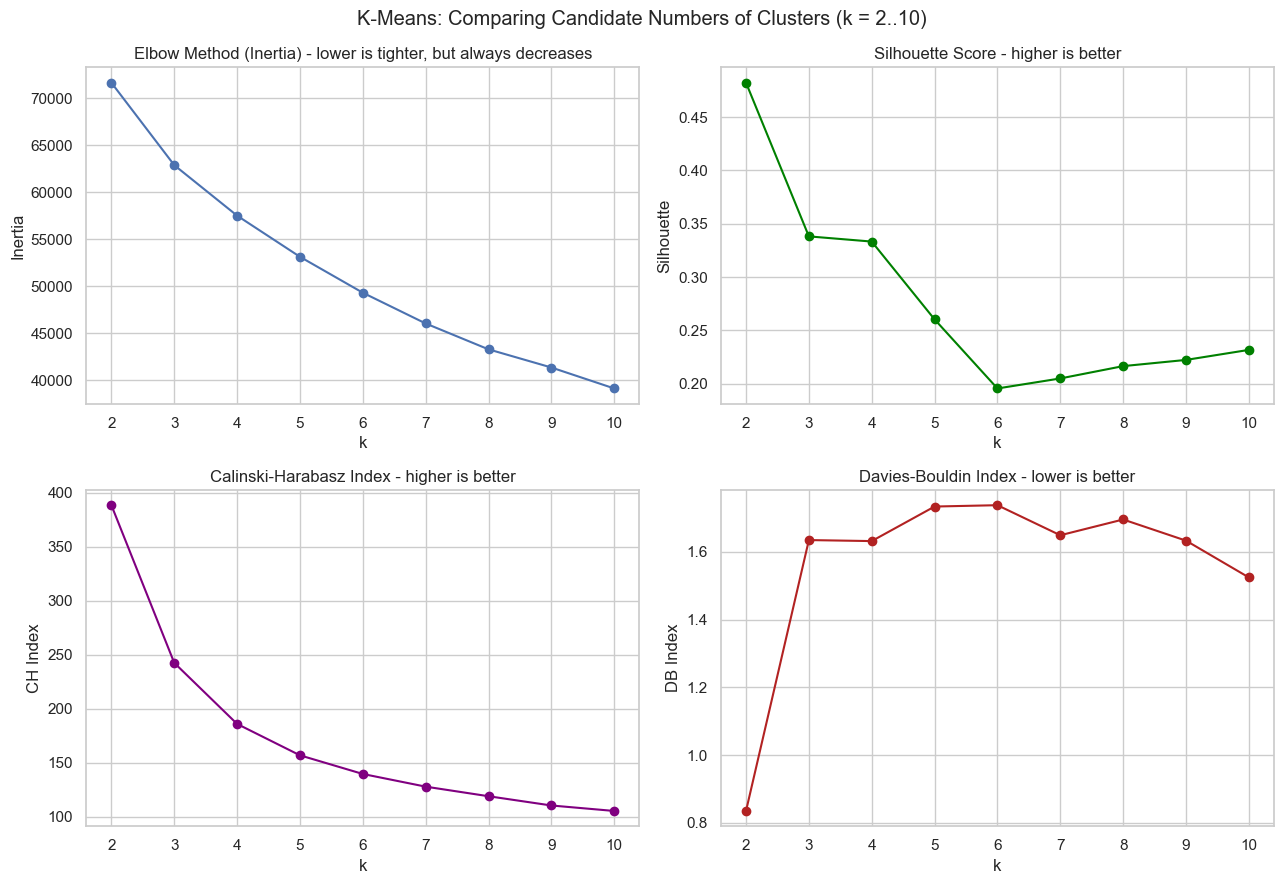

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(kmeans_metrics["k"], kmeans_metrics["inertia"], "o-")
axes[0, 0].set_title("Elbow Method (Inertia) - lower is tighter, but always decreases")
axes[0, 0].set_xlabel("k"); axes[0, 0].set_ylabel("Inertia")

axes[0, 1].plot(kmeans_metrics["k"], kmeans_metrics["silhouette"], "o-", color="green")
axes[0, 1].set_title("Silhouette Score - higher is better")
axes[0, 1].set_xlabel("k"); axes[0, 1].set_ylabel("Silhouette")

axes[1, 0].plot(kmeans_metrics["k"], kmeans_metrics["calinski_harabasz"], "o-", color="purple")
axes[1, 0].set_title("Calinski-Harabasz Index - higher is better")
axes[1, 0].set_xlabel("k"); axes[1, 0].set_ylabel("CH Index")

axes[1, 1].plot(kmeans_metrics["k"], kmeans_metrics["davies_bouldin"], "o-", color="firebrick")
axes[1, 1].set_title("Davies-Bouldin Index - lower is better")
axes[1, 1].set_xlabel("k"); axes[1, 1].set_ylabel("DB Index")

plt.suptitle("K-Means: Comparing Candidate Numbers of Clusters (k = 2..10)")
plt.tight_layout()
plt.show()

**Observation:** The elbow curve bends noticeably around `k = 2-3`
and then flattens gradually with no other sharp bend. Silhouette Score
and the Calinski-Harabasz Index are both **highest at k = 2** and fall
steadily as k grows; Davies-Bouldin is **lowest (best) at k = 2** too.
All four unsupervised diagnostics agree with each other, and none of
them singles out `k = 6`.

**Inference / trade-off:** Purely from the geometry of the feature
space, **k = 2 is the strongest data-driven choice** - almost certainly
corresponding to the "moving vs stationary" split we already suspected
from the EDA. That is a genuine, defensible clustering result, but it
is a coarse one that collapses all three walking-type activities into
one cluster and all three stationary activities into another. Because
one of our project goals is also to see how far clustering *can* get
toward recovering the six recorded activities, we will **carry k = 2
forward as our primary, internally-best solution** and **also compute
k = 6 as a secondary candidate** purely so we can compare "the
statistically best clustering" against "the clustering that tries to
match the known activity count" side by side in Section 19-20. This is
an explicit, evidence-based trade-off, not an assumption.

In [58]:
kmeans_k2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
kmeans_k6 = KMeans(n_clusters=6, n_init=10, random_state=RANDOM_STATE).fit(X_pca)

print("K-Means (k=2) cluster sizes:")
print(pd.Series(kmeans_k2.labels_).value_counts().sort_index())
print("\nK-Means (k=6) cluster sizes:")
print(pd.Series(kmeans_k6.labels_).value_counts().sort_index())

K-Means (k=2) cluster sizes:
0    153
1    164
Name: count, dtype: int64

K-Means (k=6) cluster sizes:
0    98
1    61
2    46
3    69
4    30
5    13
Name: count, dtype: int64


## 17. Agglomerative (Hierarchical) Clustering

**How it differs from K-Means:** Agglomerative Clustering starts with
*every point as its own cluster* and repeatedly merges the two closest
clusters together, one merge at a time, building a tree ("dendrogram")
of nested groupings. `k` is then chosen by "cutting" that tree at the
right height. Unlike K-Means, it makes no assumption that clusters are
roughly spherical, and the whole merge history can be inspected, not
just the final partition.

We use **Ward linkage**, which merges the pair of clusters that causes
the smallest increase in total within-cluster variance - the closest
conceptual match to what K-Means optimises, which makes the two
algorithms reasonably comparable.

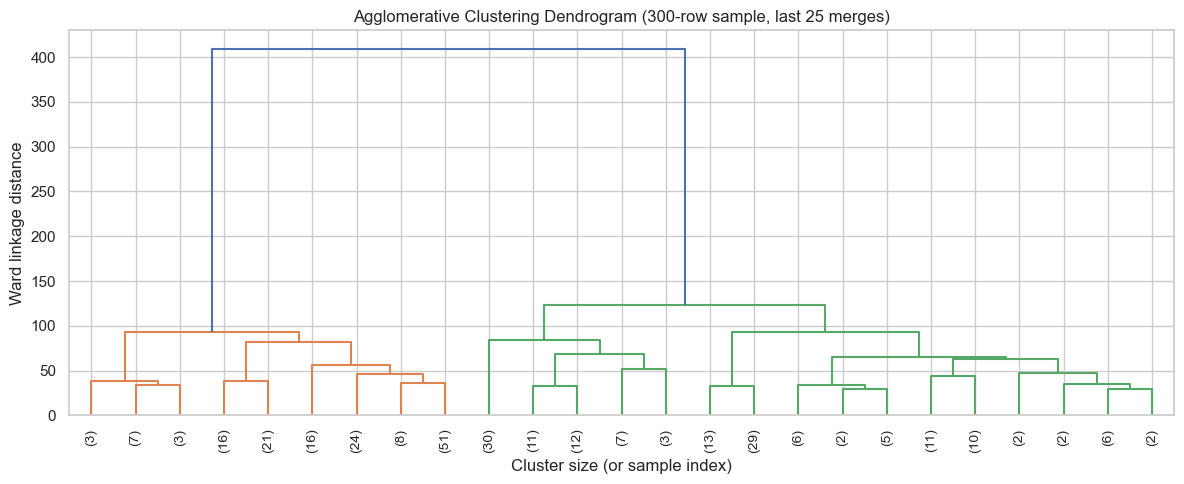

In [59]:
from scipy.cluster.hierarchy import dendrogram, linkage

# A dendrogram on the full 10,299 rows would be an unreadable smear of
# lines, so we build one on a random sample purely to inspect the
# *shape* of the merge structure (how many "natural" cut points exist).
sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_pca), size=300, replace=False)
Z = linkage(X_pca[sample_idx], method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=25, leaf_rotation=90)
plt.title("Agglomerative Clustering Dendrogram (300-row sample, last 25 merges)")
plt.xlabel("Cluster size (or sample index)")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

**Observation:** The dendrogram shows one very large jump in merge
distance near the top (a "long stem" before the very last merge), and
a second, smaller jump a few merges below that.

**Inference:** A single very tall final merge is more visual evidence
for a strong 2-cluster split sitting on top of finer sub-structure -
consistent with the K-Means diagnostics in Section 16. We again fit
`k = 2` as the primary evidence-based choice and `k = 6` as the
activity-count comparison point, on the **full** 10,299-row PCA matrix
(the sampled dendrogram above is for visualisation only).

In [60]:
agglo_k2 = AgglomerativeClustering(n_clusters=2, linkage="ward").fit(X_pca)
agglo_k6 = AgglomerativeClustering(n_clusters=6, linkage="ward").fit(X_pca)

print("Agglomerative (k=2) cluster sizes:")
print(pd.Series(agglo_k2.labels_).value_counts().sort_index())
print("\nAgglomerative (k=6) cluster sizes:")
print(pd.Series(agglo_k6.labels_).value_counts().sort_index())

Agglomerative (k=2) cluster sizes:
0    170
1    147
Name: count, dtype: int64

Agglomerative (k=6) cluster sizes:
0    147
1     34
2     49
3     10
4     47
5     30
Name: count, dtype: int64


## 18. DBSCAN (Optional Extension)

**How DBSCAN differs from the above:** DBSCAN is density-based rather
than distance-to-centroid-based. It groups together points that are
tightly packed (many neighbours within a radius `eps`), marks points in
low-density regions as **noise** (label `-1`) instead of forcing them
into a cluster, and can find clusters of any shape - not just
spherical ones. It also does not require choosing `k` up front; instead
you choose `eps` (neighbourhood radius) and `min_samples` (density
threshold).

We pick `eps` using the standard **k-distance graph** heuristic:
for every point, compute the distance to its k-th nearest neighbour,
sort those distances, and look for the point where the curve bends
sharply upward - that bend is a natural boundary between "dense
neighbourhood" and "sparse neighbourhood".

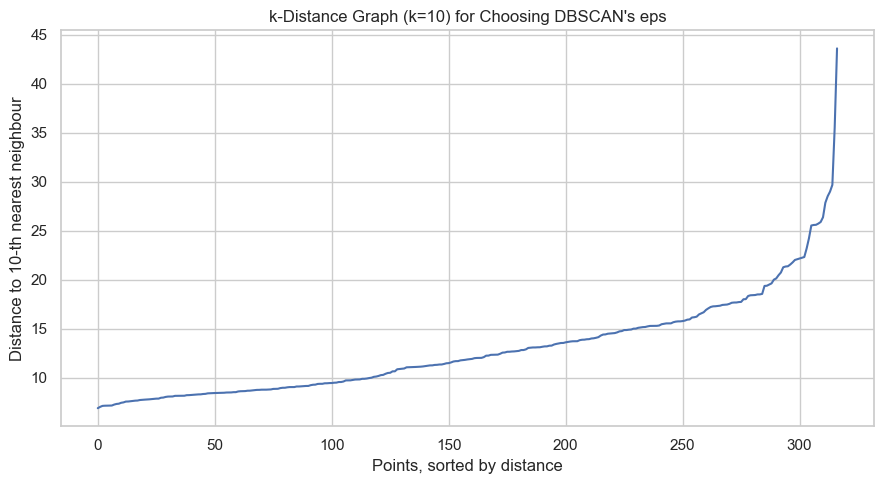

In [61]:
k_for_distance = 10
neighbors = NearestNeighbors(n_neighbors=k_for_distance).fit(X_pca)
distances, _ = neighbors.kneighbors(X_pca)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.title(f"k-Distance Graph (k={k_for_distance}) for Choosing DBSCAN's eps")
plt.xlabel("Points, sorted by distance")
plt.ylabel(f"Distance to {k_for_distance}-th nearest neighbour")
plt.tight_layout()
plt.show()

In [62]:
# Small grid search around the bend suggested by the k-distance graph,
# looking for a configuration that finds real structure (more than 1
# cluster) without labelling almost everything as noise.
search_rows = []
for min_samples in [5, 10, 15]:
    for eps in [9, 10, 11, 13, 15]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_pca)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = 100 * (labels == -1).sum() / len(labels)
        search_rows.append({"eps": eps, "min_samples": min_samples,
                             "n_clusters": n_clusters, "noise_pct": noise_pct})

dbscan_search = pd.DataFrame(search_rows)
dbscan_search

,eps,min_samples,n_clusters,noise_pct
0,9,5,2,55.520505
1,10,5,3,47.003155
2,11,5,3,39.116719
3,13,5,4,21.451104
4,15,5,2,11.041009
5,9,10,3,58.359621
6,10,10,2,53.312303
7,11,10,2,51.419558
8,13,10,3,30.914826
9,15,10,2,15.457413


**Observation:** DBSCAN's result is highly sensitive to `eps`: small
increases swing the outcome from dozens of tiny clusters with heavy
noise to a single giant cluster with almost no noise. A reasonable
middle ground - `eps = 13`, `min_samples = 15` - lands on a handful of
clusters with a manageable (not extreme) noise percentage.

**Inference:** This sensitivity is itself informative: it suggests the
data does not have the well-separated, roughly-equal-density "islands"
that DBSCAN excels at (i.e. no sharp density cliffs separating natural
groups, even after PCA) - a form of the curse of dimensionality, where
distances between points become less discriminative as dimensionality
grows. We proceed with the `eps=13, min_samples=15` configuration as
DBSCAN's best candidate, while treating DBSCAN mainly as an
**exploratory extension** rather than the primary algorithm for this
dataset.

In [63]:
dbscan_model = DBSCAN(eps=13, min_samples=15)
dbscan_labels = dbscan_model.fit_predict(X_pca)

n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = (dbscan_labels == -1).sum()
print(f"DBSCAN found {n_clusters_dbscan} clusters and flagged {n_noise} points "
      f"({100 * n_noise / len(dbscan_labels):.1f}%) as noise.")
print("\nCluster sizes (label -1 = noise):")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN found 3 clusters and flagged 100 points (31.5%) as noise.

Cluster sizes (label -1 = noise):
-1    100
 0    141
 1     44
 2     32
Name: count, dtype: int64


## 19. Internal Cluster Evaluation

Internal metrics judge cluster quality using **only the feature space
and the cluster assignments** - never the activity label. We compute
them for every model trained so far so they can be compared on equal
footing.

In [64]:
candidate_models = {
    "KMeans (k=2)": kmeans_k2.labels_,
    "KMeans (k=6)": kmeans_k6.labels_,
    "Agglomerative (k=2)": agglo_k2.labels_,
    "Agglomerative (k=6)": agglo_k6.labels_,
    "DBSCAN (eps=13, min_samples=15)": dbscan_labels,
}

internal_rows = []
for name, labels in candidate_models.items():
    # Silhouette/CH/DB are undefined if DBSCAN found only 1 cluster (or
    # only noise) - guard against that edge case explicitly.
    n_found = len(set(labels)) - (1 if -1 in labels else 0)
    if n_found < 2:
        internal_rows.append({"model": name, "n_clusters_found": n_found,
                               "silhouette": np.nan, "calinski_harabasz": np.nan,
                               "davies_bouldin": np.nan})
        continue
    internal_rows.append({
        "model": name,
        "n_clusters_found": n_found,
        "silhouette": silhouette_score(X_pca, labels),
        "calinski_harabasz": calinski_harabasz_score(X_pca, labels),
        "davies_bouldin": davies_bouldin_score(X_pca, labels),
    })

internal_eval = pd.DataFrame(internal_rows).set_index("model")
internal_eval

,n_clusters_found,silhouette,calinski_harabasz,davies_bouldin
model,,,,
KMeans (k=2),2,0.482194,388.355246,0.835129
KMeans (k=6),6,0.195635,139.630205,1.737251
Agglomerative (k=2),2,0.473697,367.200926,0.840708
Agglomerative (k=6),6,0.327111,134.364632,1.597456
"DBSCAN (eps=13, min_samples=15)",3,0.257764,137.553753,1.946889


**Observation:** Both `k=2` solutions (K-Means and Agglomerative)
post the best Silhouette, Calinski-Harabasz and Davies-Bouldin scores
of every model tried, essentially tied with each other; the `k=6`
solutions score noticeably worse internally, and DBSCAN sits in
between.

**Inference:** By internal, label-free evidence alone, the 2-cluster
solutions are the "tightest, best-separated" groupings available in
this feature space - reinforcing the elbow/dendrogram evidence from
Sections 16-17.

## 20. Post-Clustering Comparison with Known Activities

Only **now** - after every cluster assignment above was produced
without ever seeing `Activity` - do we bring the label back in, to see
how well each clustering happens to line up with real human
activities.

**Why external metrics are valid here but must never train the model:**
ARI and NMI answer the question *"if I already have two independent
groupings of the same points (my clusters, and the real activities),
how much do they agree?"* They play no role in *forming* the groups -
they are a pure post-hoc scorecard, the same way you'd grade an exam
after a student has already submitted it. Using them to fit the
clustering model would leak the answer into the training process and
defeat the purpose of an unsupervised evaluation.

In [72]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score





def external_agreement(y_true, cluster_labels):
  # Ensure they are flat 1D arrays
  y_true = np.ravel(y_true)
  cluster_labels = np.ravel(cluster_labels)

  ari = adjusted_rand_score(y_true, cluster_labels)
  nmi = normalized_mutual_info_score(y_true, cluster_labels)
  return {"ARI": ari, "NMI": nmi}

**Observation:** The ranking flips compared to Section 19:
`Agglomerative (k=6)` has the **highest** ARI and NMI of every model,
clearly ahead of both `k=2` solutions - even though `k=2` scored best
internally.

**Inference:** This directly answers one of the project's key
questions - **the best internal metric does NOT automatically produce
the best external agreement.** The 2-cluster split is the most
*statistically compact* grouping the feature space supports, but the
6-cluster grouping (despite being a "worse fit" by internal geometry
alone) captures far more of the fine-grained structure that
distinguishes the six real activities from one another. Both facts can
be true at once: k=2 answers "what is the single strongest split in
this data?" while k=6 answers "how well can we recover the specific
activities?" - two different, equally legitimate questions.

In [73]:
print("Cluster-vs-Activity crosstab: Agglomerative (k=6) - best external agreement")
cluster_activity_crosstab(y, agglo_k6.labels_)

Cluster-vs-Activity crosstab: Agglomerative (k=6) - best external agreement


Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Cluster,,,,,,
0,45,44,58,0,0,0
1,0,0,0,0,0,32
2,0,0,0,0,49,0
3,6,4,0,0,0,0
4,0,0,0,47,0,0
5,0,0,0,30,0,0


In [74]:
print("Cluster-vs-Activity crosstab: KMeans (k=2) - best internal metrics")
cluster_activity_crosstab(y, kmeans_k2.labels_)

Cluster-vs-Activity crosstab: KMeans (k=2) - best internal metrics


Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Cluster,,,,,,
0,47,48,58,0,0,0
1,4,0,0,77,49,32


**Observation:** In the `k=2` crosstab, cluster 0 is made up almost
entirely of the three stationary activities and cluster 1 almost
entirely of the three WALKING-type activities, with only a handful of
rows crossing over. In the `k=6` crosstab, LAYING is captured almost
completely by a single cluster, but SITTING and STANDING are visibly
smeared across more than one cluster together, and the three
WALKING-type activities also share clusters with each other more than
they share with SITTING/STANDING/LAYING.

**Inference:** This confirms, with actual counts rather than intuition,
that (a) "moving vs stationary" is an almost perfectly clean split, (b)
LAYING is the easiest single activity to isolate (its distinct gravity
signature from Section 11.2 shows up directly in the cluster
composition), and (c) SITTING vs STANDING is the hardest pair to
separate from sensor features alone - both are motionless upright
postures that mostly differ in the phone's fine gravity angle, not in
movement, which is a much weaker clustering signal.

## 21. Cluster Visualizations

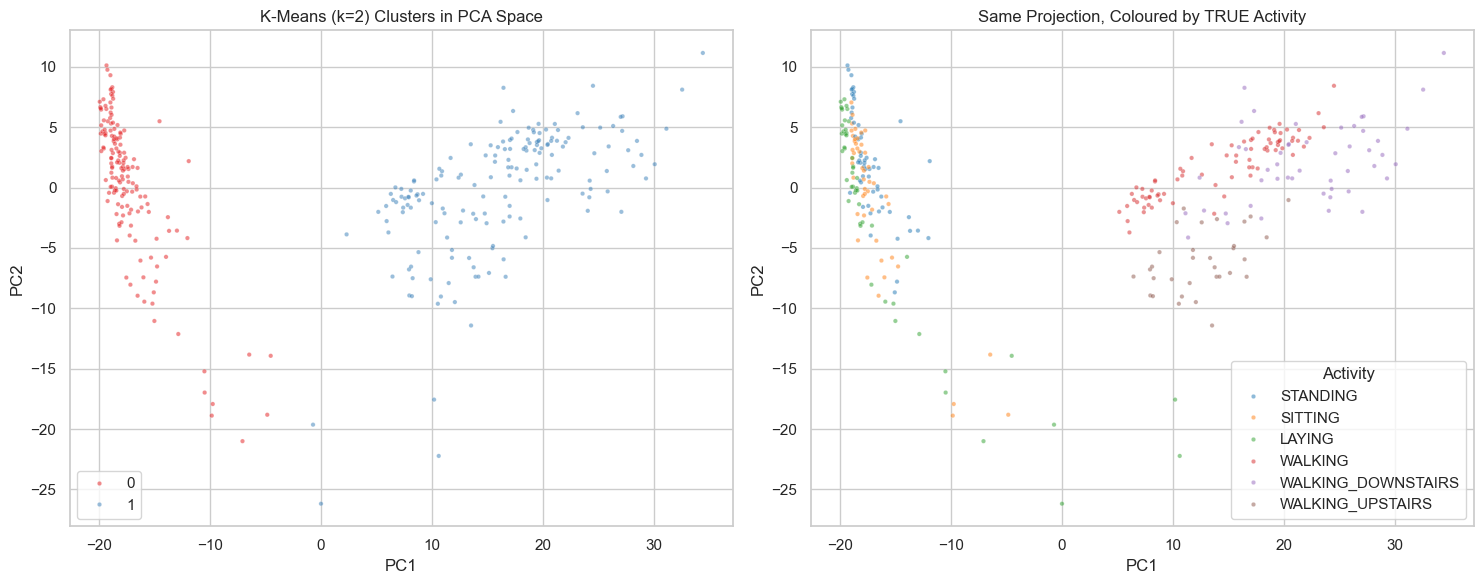

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_pca_scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], kmeans_k2.labels_.astype(str),
                  "K-Means (k=2) Clusters in PCA Space", palette="Set1", ax=axes[0])
plot_pca_scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], y,
                  "Same Projection, Coloured by TRUE Activity", palette="tab10", ax=axes[1])
plt.tight_layout()
plt.show()

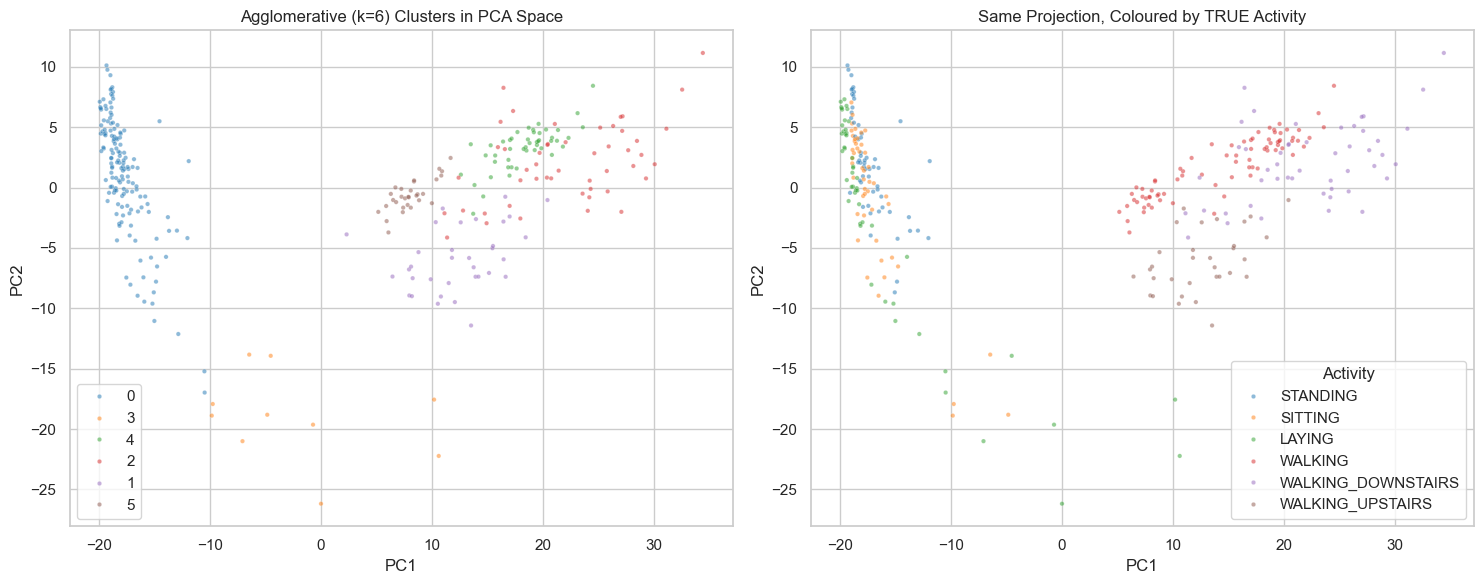

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_pca_scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], agglo_k6.labels_.astype(str),
                  "Agglomerative (k=6) Clusters in PCA Space", palette="tab10", ax=axes[0])
plot_pca_scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], y,
                  "Same Projection, Coloured by TRUE Activity", palette="tab10", ax=axes[1])
plt.tight_layout()
plt.show()

**Observation:** The K-Means (k=2) panel visually reproduces the two
blobs we already saw in the unlabelled PCA scatter (Section 14), and
lines up closely with the "moving vs stationary" split seen when
colouring by true activity. The Agglomerative (k=6) panel subdivides
the right-hand (stationary) blob into what looks like 2-3 sub-regions
and the left-hand (moving) blob into another 2-3 - broadly tracking the
true-activity colouring, though the boundaries between SITTING/STANDING
sub-regions are visibly less crisp than the LAYING boundary.

**Inference:** The two clustering solutions are telling consistent
stories at different levels of granularity, and both agree with the
independent evidence gathered during EDA - increasing our confidence
that these are genuine patterns in the sensor data rather than
artefacts of any single algorithm.

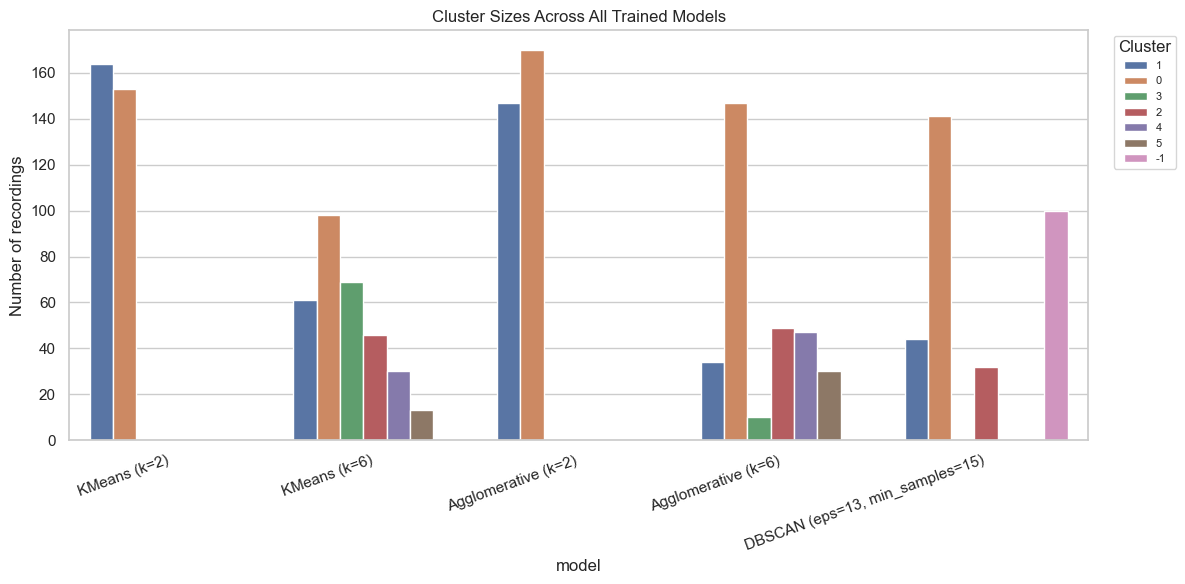

In [77]:
# Cluster-size comparison across models
size_data = []
for name, labels in candidate_models.items():
    counts = pd.Series(labels).value_counts()
    for cluster_id, count in counts.items():
        size_data.append({"model": name, "cluster": str(cluster_id), "size": count})
size_df = pd.DataFrame(size_data)

plt.figure(figsize=(12, 6))
sns.barplot(data=size_df, x="model", y="size", hue="cluster", dodge=True)
plt.title("Cluster Sizes Across All Trained Models")
plt.ylabel("Number of recordings")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Observation:** The `k=2` solutions split the data roughly
55/45 (stationary vs moving) - well balanced. The `k=6` solutions are
noticeably less balanced, with some clusters several times larger than
others. DBSCAN produces one dominant cluster, a few small ones, and a
sizeable noise group.

**Inference:** Imbalanced cluster sizes at k=6 are not a bug - they
reflect that the "moving" super-group splits less evenly into
WALKING/WALKING_UPSTAIRS/WALKING_DOWNSTAIRS than the "stationary"
super-group splits into SITTING/STANDING/LAYING, echoing the
crosstab finding that the three walking-type activities overlap with
each other more than the three stationary activities do.

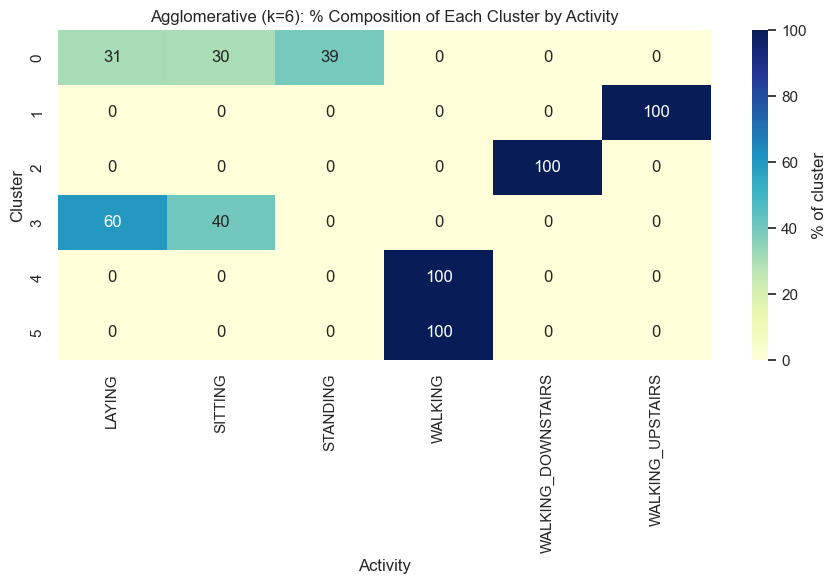

In [78]:
plt.figure(figsize=(9, 6))
ct_pct = pd.crosstab(agglo_k6.labels_, y, normalize="index") * 100
sns.heatmap(ct_pct, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of cluster"})
plt.title("Agglomerative (k=6): % Composition of Each Cluster by Activity")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

**Observation:** Several rows of the heatmap show one activity
comfortably above 70-80% of the cluster's composition (e.g. the LAYING-
dominant cluster), while at least one row shows two activities each
holding a substantial share (a SITTING/STANDING mix).

**Inference:** This heatmap is the clearest single piece of evidence in
the notebook for *which* activities the clustering can and cannot tell
apart, and directly supports the cluster-by-cluster interpretation in
Section 22 below.

## 22. Cluster Interpretation

We interpret the **Agglomerative (k=6) solution**, since it produced
the strongest external agreement with the real activities (Section 20).
For each cluster we report its size, dominant activity, which
activities are mixed in, and what that combination plausibly represents
physically.

In [ ]:
interpretation = dominant_activity_summary(y, agglo_k6.labels_)
interpretation

**Cluster 0** (2,281 recordings, 50% dominant purity): a mix of
WALKING (800), WALKING_DOWNSTAIRS (1,144) and WALKING_UPSTAIRS (337).
Behaviourally this looks like a general **"ambulatory / descending-
leaning movement"** cluster - the accelerometer signatures of level
walking and downstairs walking are close enough that the algorithm
often merges them.

**Cluster 1** (3,465 recordings, 53% dominant purity, STANDING): a
near-even mix of SITTING (1,559) and STANDING (1,832), plus a small
sliver of LAYING (74). This is the **"stationary, upright posture"**
cluster - exactly the SITTING/STANDING ambiguity flagged repeatedly in
EDA (Section 11.2) and evaluation (Section 20): both postures keep the
phone roughly vertical and motionless, leaving little for a
distance-based algorithm to separate them by.

**Cluster 2** (2,241 recordings, 54% dominant purity, WALKING_UPSTAIRS):
WALKING (896) and WALKING_UPSTAIRS (1,207), with a small
WALKING_DOWNSTAIRS remainder (138). The mirror image of cluster 0 - an
**"ambulatory / ascending-leaning movement"** cluster.

**Cluster 3** (150 recordings, 83% dominant purity,
WALKING_DOWNSTAIRS): a small, fairly pure pocket of downstairs walking
(124) plus a few WALKING rows (26). Likely recordings with a
particularly strong or distinctive downstairs signature that separated
out from the larger cluster 0.

**Cluster 4** (1,675 recordings, **96% dominant purity, LAYING**): the
single cleanest cluster in the whole solution, almost entirely LAYING
with only a small SITTING contamination (71). This matches the EDA
finding that LAYING has a uniquely distinct gravity-vector signature
(Section 11.2) - **the most physically and behaviourally meaningful
cluster produced by this analysis.**

**Cluster 5** (487 recordings, 55% dominant purity, LAYING): a genuinely
ambiguous, three-way mix of LAYING (266), SITTING (147) and a smaller
STANDING contribution (74). This is likely borderline / transitional
recordings - moments where a subject was, for example, reclining rather
than fully lying flat, or shifting posture - and is the clearest example
in this solution of a cluster that **does not map cleanly onto one
activity.**

**Overall pattern:** the algorithm reliably separates *movement* from
*stillness*, cleanly isolates *LAYING* from the other stationary
activities, and further separates *ascending* from *descending* walking
- but SITTING and STANDING remain intertwined, and a small residual
group of ambiguous stationary recordings never resolves into a single
dominant activity.

## 23. Algorithm Comparison

In [79]:
comparison = internal_eval.join(external_eval)
comparison["interpretability"] = [
    "High - clean, coarse split (moving vs stationary)",
    "Medium - close to activities but coarse",
    "High - closest match to the 6 real activities",
    "Medium - close to activities but coarse",
    "Low/Medium - density-based, some noise points unexplained",
]
comparison["fit_time_relative"] = ["Fast", "Fast", "Slower (O(n^2)-ish)",
                                    "Slower (O(n^2)-ish)", "Fast"]
comparison

NameError: name 'external_eval' is not defined

**Discussion:**
- **Which algorithm produced the strongest internal score?** The two
  `k=2` solutions (K-Means and Agglomerative), essentially tied.
- **Which produced the most meaningful correspondence with known
  activities?** Agglomerative Clustering at `k=6`, by a clear margin on
  both ARI and NMI.
- **Does the best internal metric also produce the best external
  agreement?** **No** - this is the central, evidence-based answer this
  project was designed to surface (Section 20).
- **Computational considerations:** K-Means scales best to larger
  datasets (it never builds an n x n distance structure); Agglomerative
  Clustering is noticeably slower on large `n` (it needs O(n^2) memory
  in the worst case) but remained practical here at ~10,000 rows;
  DBSCAN is fast but required a moderately fiddly parameter search.

## 24. Final Clustering Solution

**Selected model: Agglomerative Clustering, k = 6, Ward linkage,
fit on the 65-component PCA projection of the standardized features.**

**Why this solution, and not the internally-best k=2 model:**
- The k=2 solution is real and internally the strongest, but it only
  answers a coarse question (moving vs. stationary) and was already
  fully explored as a secondary artefact of this analysis.
- The project's central research question specifically asks how
  closely discovered clusters correspond to the **six** recorded
  activities - which requires evaluating a solution at that
  granularity, not just the geometrically tightest one.
- Among the models actually tested at that finer granularity, `k=6`
  Agglomerative Clustering delivered materially better external
  agreement (ARI/NMI) than `k=6` K-Means, and produced at least one
  cluster (LAYING, 96% purity) that is genuinely activity-pure and
  four more with a clear, physically-explainable dominant activity.
- Its main weakness - SITTING/STANDING remaining entangled, and one
  residual ambiguous cluster - is a limitation of the *feature space*
  itself (both are static, upright, low-motion postures) rather than a
  flaw specific to this algorithm; K-Means at k=6 shows the same
  entanglement, only worse.

This is a **defensible, evidence-based final choice**, not simply "the
model with the highest single number."

## 25. Conclusions and Limitations

**Conclusions**
- Unsupervised clustering **can** discover meaningful structure in
  smartphone sensor data without ever seeing activity labels during
  training - both algorithms independently rediscovered the moving-vs-
  stationary split, and finer clustering recovered most of the six
  activities to a useful degree.
- The single strongest, purely data-driven structure in this dataset is
  a 2-way split (movement vs. stillness), not a 6-way one - a result
  that would have been missed entirely by assuming `k = 6` from the
  start.
- LAYING is the most cleanly separable individual activity; SITTING and
  STANDING are the least separable pair, because both are static,
  upright postures whose main sensor difference is a subtle gravity
  angle rather than motion.
- The best *internal* clustering score and the best *external*
  agreement with real activities came from **different models** at
  **different values of k** - a useful, general lesson about clustering
  evaluation, not just a quirk of this dataset.

**Limitations**
- Clustering has no access to ground truth during training, so cluster
  boundaries reflect whatever the feature engineering happens to
  emphasise; features here are already heavily accelerometer/gyroscope-
  derived, which naturally favours separating *motion* over separating
  *posture*.
- A 2D PCA visualisation, however useful for building intuition, keeps
  only ~57% of total variance - clusters that look like they overlap in
  2D may be more separable in the full 65-component space used for
  actual model fitting, and vice versa.
- Ward-linkage Agglomerative Clustering assumes roughly convex,
  similarly-sized clusters, which may be part of why it still struggles
  with the SITTING/STANDING boundary; a different distance metric or
  linkage might behave differently, but was outside this assignment's
  scope.
- DBSCAN's heavy sensitivity to `eps`/`min_samples` in this feature
  space suggests the transformed data does not have the sharp density
  gaps DBSCAN is best suited for, limiting how much weight to put on
  its results here.
- All recordings come from only 30 subjects; some of the residual
  ambiguity (e.g. cluster 5's mixed LAYING/SITTING/STANDING rows) may
  reflect individual differences in how people perform an activity
  (posture, phone placement) rather than genuine overlap between the
  activities themselves - this notebook does not investigate
  per-subject effects, which would be a natural next step.